## 1. Load and explore the data

Loaded the supplied CSV-format dataset files, confirmed their dimensions and missing values, checked the class distribution, and displayed sample handwritten digits. The last column is the label and the first 64 columns are pixel values.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.base import clone

RANDOM_STATE = 42
DATA_DIR = Path.cwd()
train_path = DATA_DIR / 'optdigits.tra'
test_path = DATA_DIR / 'optdigits.tes'
assert train_path.exists() and test_path.exists(), (
    'Place optdigits.tra and optdigits.tes in the same folder as this notebook.')

train_df = pd.read_csv(train_path, header=None)
test_df = pd.read_csv(test_path, header=None)
feature_cols = [f'pixel_{i}' for i in range(64)]
train_df.columns = feature_cols + ['digit']
test_df.columns = feature_cols + ['digit']

print('Uploaded training shape:', train_df.shape)
print('Uploaded testing shape: ', test_df.shape)
print('Missing values:', int(train_df.isna().sum().sum() + test_df.isna().sum().sum()))
print('Pixel range:', int(train_df[feature_cols].min().min()), 'to',
      int(train_df[feature_cols].max().max()))
display(train_df.head(3))

assert train_df.shape == (3823, 65) and test_df.shape == (1797, 65)
assert not train_df.isna().any().any() and not test_df.isna().any().any()
assert set(train_df['digit']) == set(range(10))
assert set(test_df['digit']) == set(range(10))

Uploaded training shape: (3823, 65)
Uploaded testing shape:  (1797, 65)
Missing values: 0
Pixel range: 0 to 16


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,pixel_10,pixel_11,pixel_12,pixel_13,pixel_14,pixel_15,pixel_16,pixel_17,pixel_18,pixel_19,pixel_20,pixel_21,pixel_22,pixel_23,pixel_24,pixel_25,pixel_26,pixel_27,pixel_28,pixel_29,pixel_30,pixel_31,pixel_32,pixel_33,pixel_34,pixel_35,pixel_36,pixel_37,pixel_38,pixel_39,pixel_40,pixel_41,pixel_42,pixel_43,pixel_44,pixel_45,pixel_46,pixel_47,pixel_48,pixel_49,pixel_50,pixel_51,pixel_52,pixel_53,pixel_54,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,digit
0,0,1,6,15,12,1,0,0,0,7,16,6,6,10,0,0,0,8,16,2,0,11,2,0,0,5,16,3,0,5,7,0,0,7,13,3,0,8,7,0,0,4,12,0,1,13,5,0,0,0,14,9,15,9,0,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,16,8,16,5,0,0,0,11,16,0,6,14,3,0,0,12,12,0,0,11,11,0,0,12,12,0,0,8,12,0,0,7,15,1,0,13,11,0,0,0,16,8,10,15,3,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,11,9,11,16,1,0,0,0,0,0,7,14,0,0,0,0,3,4,14,12,2,0,0,1,16,16,16,16,10,0,0,2,12,16,10,0,0,0,0,0,2,16,4,0,0,0,0,0,9,14,0,0,0,0,7


load_digits() shape: (1797, 64)
Identical to uploaded test images: True
Identical to uploaded test labels: True


,Training,Testing
Digit,,
0,376,178
1,389,182
2,380,177
3,389,183
4,387,181
5,376,182
6,377,181
7,387,179
8,380,174


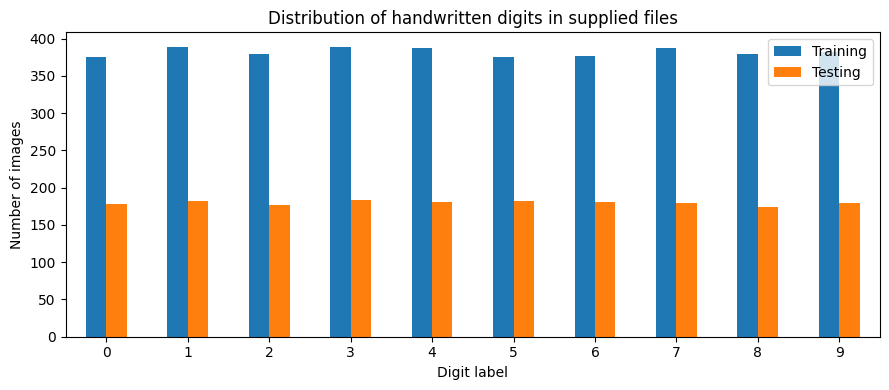

In [2]:
# The 1,797 examples returned by scikit-learn match the supplied test file.
sklearn_digits = load_digits()
same_images = np.array_equal(sklearn_digits.data, test_df[feature_cols].to_numpy())
same_labels = np.array_equal(sklearn_digits.target, test_df['digit'].to_numpy())
print('load_digits() shape:', sklearn_digits.data.shape)
print('Identical to uploaded test images:', same_images)
print('Identical to uploaded test labels:', same_labels)
assert same_images and same_labels

class_counts = pd.DataFrame({
    'Training': train_df['digit'].value_counts().sort_index(),
    'Testing': test_df['digit'].value_counts().sort_index()
})
class_counts.index.name = 'Digit'
display(class_counts)
class_counts.plot(kind='bar', figsize=(9, 4), rot=0)
plt.title('Distribution of handwritten digits in supplied files')
plt.xlabel('Digit label')
plt.ylabel('Number of images')
plt.tight_layout()
plt.show()

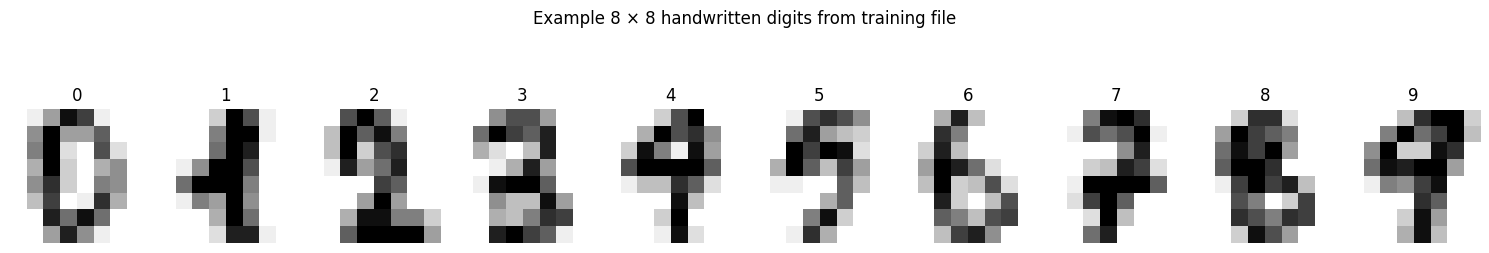

In [3]:
# Display one training image for each label 0–9.
fig, axes = plt.subplots(1, 10, figsize=(15, 2.5))
for digit, ax in enumerate(axes):
    sample = train_df.loc[train_df['digit'].eq(digit), feature_cols].iloc[0]
    ax.imshow(sample.to_numpy().reshape(8, 8), cmap='gray_r', vmin=0, vmax=16)
    ax.set_title(str(digit))
    ax.axis('off')
fig.suptitle('Example 8 × 8 handwritten digits from training file', y=1.10)
plt.tight_layout()
plt.show()

## 2. Split data for training and testing

The uploaded files already provided an **official 3,823-image training set** and a **separate 1,797-image writer-independent test set**. Within the official training set, used `train_test_split` with an **80%/20% stratified split** to create development-training and validation subsets. Tuned and chose models using only these development data; used the official test set only for final reporting. This prevents test-data leakage.

In [4]:
X_full = train_df[feature_cols].to_numpy()
y_full = train_df['digit'].to_numpy()
X_test = test_df[feature_cols].to_numpy()
y_test = test_df['digit'].to_numpy()

X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.20, stratify=y_full,
    random_state=RANDOM_STATE
)
print(f'Development train: {len(y_train)} images')
print(f'Development validation: {len(y_val)} images')
print(f'Untouched official test: {len(y_test)} images')
print('Classes in each subset:', np.unique(y_train), np.unique(y_val), np.unique(y_test))

Development train: 3058 images
Development validation: 765 images
Untouched official test: 1797 images
Classes in each subset: [0 1 2 3 4 5 6 7 8 9] [0 1 2 3 4 5 6 7 8 9] [0 1 2 3 4 5 6 7 8 9]


In [ ]:
## 3. Select and build the classification models

- **KNeighborsClassifier:** predicts the digit using similar nearby digit images.
- **SVC:** separates classes using a radial-basis-function kernel for nonlinear decision boundaries.
- **GaussianNB:** a fast probabilistic baseline that assumes feature independence within each class.

The baseline KNN and SVC pipelines use `StandardScaler` **inside the training pipeline**, preventing validation/test-data leakage. Because all input pixels already use the same 0–16 scale, cross-validation also checks whether unscaled pixel values perform better. GaussianNB is trained on original pixel intensities.

In [5]:
models = {
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),
    'SVC': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', C=1.0, gamma='scale'))
    ]),
    'GaussianNB': GaussianNB()
}
print('Selected models:', ', '.join(models))

Selected models: KNN, SVC, GaussianNB


## 4. Train the baseline models

Fit each classifier on **only** the development-training images. These baseline results provided a reference for whether tuning helps.

In [6]:
fitted_baselines = {}
for name, model in models.items():
    fitted_baselines[name] = clone(model).fit(X_train, y_train)
    print(f'Trained baseline: {name}')

Trained baseline: KNN
Trained baseline: SVC
Trained baseline: GaussianNB


## 5. Make predictions

Predicted the label of every validation image. Displayed the first 12 validation cases using the baseline SVC as an example; model comparisons use all images, not just the displayed examples.

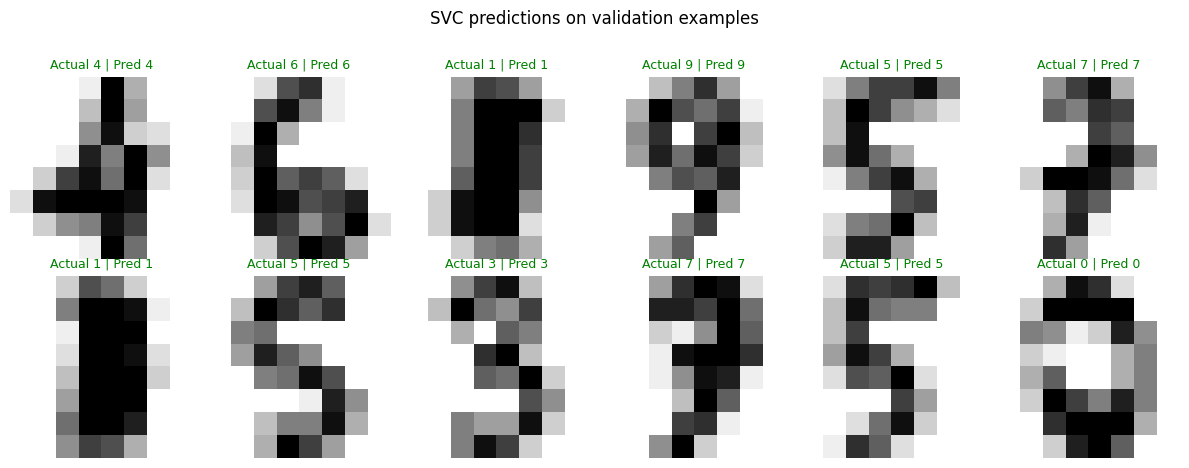

In [7]:
baseline_preds = {
    name: fitted.predict(X_val)
    for name, fitted in fitted_baselines.items()
}

fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_val[i].reshape(8, 8), cmap='gray_r', vmin=0, vmax=16)
    predicted, actual = baseline_preds['SVC'][i], y_val[i]
    ax.set_title(f'Actual {actual} | Pred {predicted}',
                 color='green' if predicted == actual else 'red', fontsize=9)
    ax.axis('off')
fig.suptitle('SVC predictions on validation examples', y=1.02)
plt.tight_layout()
plt.show()

## 6. Evaluate the baseline results

Calculated **accuracy** plus weighted precision, recall, and F1 score on the same validation set for every model. Because there are ten classes, these metrics summarize how well predictions work across all digits.

In [8]:
def scoring_row(name, stage, y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0)
    return {'Model': name, 'Stage': stage,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision, 'Recall': recall, 'F1': f1}

baseline_scores = pd.DataFrame([
    scoring_row(name, 'Baseline validation', y_val, prediction)
    for name, prediction in baseline_preds.items()
]).sort_values('Accuracy', ascending=False)
print('Baseline performance on development-validation set:')
display(baseline_scores.style.format({
    c: '{:.2%}' for c in ['Accuracy', 'Precision', 'Recall', 'F1']
}))

Baseline performance on development-validation set:


,Model,Stage,Accuracy,Precision,Recall,F1
0,KNN,Baseline validation,98.04%,98.07%,98.04%,98.04%
1,SVC,Baseline validation,97.91%,98.00%,97.91%,97.91%
2,GaussianNB,Baseline validation,79.61%,83.80%,79.61%,79.17%


## 7. Tune the models with cross-validation

Used **5-fold cross-validation** only on the development-training set. `GridSearchCV` tests several hyperparameter choices and selects the one with the best mean cross-validation accuracy. The separate validation set is then used to compare the tuned models. **The official test set is not used for tuning.**

- KNN: number of neighbors, distance weighting, and with/without standardization.
- SVC: regularization strength `C`, RBF `gamma`, and with/without standardization.
- GaussianNB: `var_smoothing` to stabilize variance estimates.

In [9]:
parameter_grids = {
    'KNN': {
        'scaler': ['passthrough', StandardScaler()],
        'model__n_neighbors': [1, 3, 5, 7, 9],
        'model__weights': ['uniform', 'distance']
    },
    'SVC': {
        'scaler': ['passthrough', StandardScaler()],
        'model__C': [0.1, 1, 10, 100],
        'model__gamma': ['scale', 0.0001, 0.001, 0.01, 0.1]
    },
    'GaussianNB': {
        'var_smoothing': [1e-12, 1e-11, 1e-10, 1e-9,
                          1e-8, 1e-7, 1e-6]
    }
}

tuned_searches = {}
for name, model in models.items():
    search = GridSearchCV(
        estimator=clone(model), param_grid=parameter_grids[name],
        cv=5, scoring='accuracy', n_jobs=-1, refit=True
    )
    search.fit(X_train, y_train)
    tuned_searches[name] = search
    print(f'{name}: CV accuracy={search.best_score_:.2%}, '
          f'best parameters={search.best_params_}')

KNN: CV accuracy=98.46%, best parameters={'model__n_neighbors': 1, 'model__weights': 'uniform', 'scaler': 'passthrough'}


SVC: CV accuracy=99.08%, best parameters={'model__C': 10, 'model__gamma': 0.001, 'scaler': 'passthrough'}
GaussianNB: CV accuracy=88.03%, best parameters={'var_smoothing': 1e-06}


## 8. Compared classifiers, select a model, and evaluate the final test set

Tuned model comparison (validation split):


,Model,Stage,Accuracy,Precision,Recall,F1,CV Accuracy,Parameters
0,SVC,Tuned validation,98.82%,98.85%,98.82%,98.82%,99.08%,"{'model__C': 10, 'model__gamma': 0.001, 'scaler': 'passthrough'}"
1,KNN,Tuned validation,98.43%,98.46%,98.43%,98.43%,98.46%,"{'model__n_neighbors': 1, 'model__weights': 'uniform', 'scaler': 'passthrough'}"
2,GaussianNB,Tuned validation,87.97%,88.73%,87.97%,87.88%,88.03%,{'var_smoothing': 1e-06}


Model selected BEFORE looking at official test results: SVC


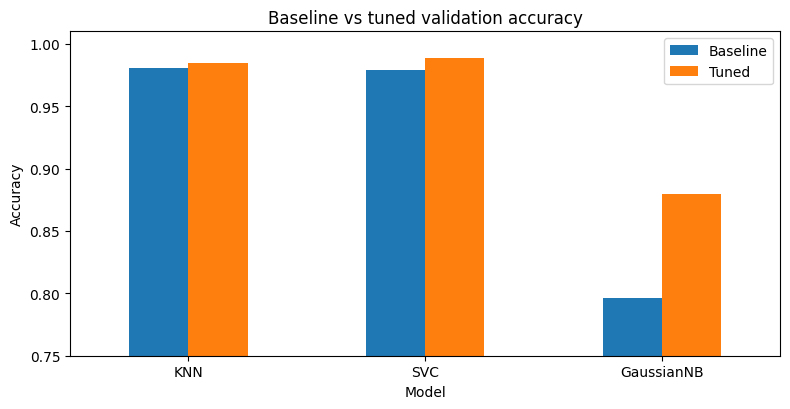

In [10]:
validation_rows = []
for name, search in tuned_searches.items():
    prediction = search.predict(X_val)
    row = scoring_row(name, 'Tuned validation', y_val, prediction)
    row['CV Accuracy'] = search.best_score_
    row['Parameters'] = str(search.best_params_)
    validation_rows.append(row)

validation_scores = pd.DataFrame(validation_rows).sort_values(
    ['Accuracy', 'CV Accuracy'], ascending=False).reset_index(drop=True)
selected_name = validation_scores.iloc[0]['Model']
print('Tuned model comparison (validation split):')
display(validation_scores.style.format({
    c: '{:.2%}' for c in ['Accuracy', 'Precision', 'Recall', 'F1', 'CV Accuracy']
}))
print('Model selected BEFORE looking at official test results:', selected_name)

comparison = pd.DataFrame({
    'Model': list(models),
    'Baseline': [baseline_scores.set_index('Model').loc[n, 'Accuracy'] for n in models],
    'Tuned': [validation_scores.set_index('Model').loc[n, 'Accuracy'] for n in models]
}).set_index('Model')
comparison.plot(kind='bar', rot=0, figsize=(8, 4.2))
plt.title('Baseline vs tuned validation accuracy')
plt.ylabel('Accuracy')
plt.ylim(0.75, 1.01)
plt.tight_layout()
plt.show()

Final results on 1,797 original held-out writer-independent images:


,Model,Stage,Accuracy,Precision,Recall,F1
0,SVC,Writer-independent test,98.27%,98.31%,98.27%,98.28%
1,KNN,Writer-independent test,98.00%,98.02%,98.00%,98.00%
2,GaussianNB,Writer-independent test,86.25%,87.55%,86.25%,86.40%


Full classification report for the validation-selected model: SVC
              precision    recall  f1-score   support

           0      0.994     1.000     0.997       178
           1      0.958     0.995     0.976       182
           2      1.000     0.983     0.991       177
           3      0.984     0.978     0.981       183
           4      1.000     1.000     1.000       181
           5      0.978     0.989     0.984       182
           6      1.000     0.994     0.997       181
           7      0.994     0.955     0.974       179
           8      0.982     0.954     0.968       174
           9      0.941     0.978     0.959       180

    accuracy                          0.983      1797
   macro avg      0.983     0.983     0.983      1797
weighted avg      0.983     0.983     0.983      1797



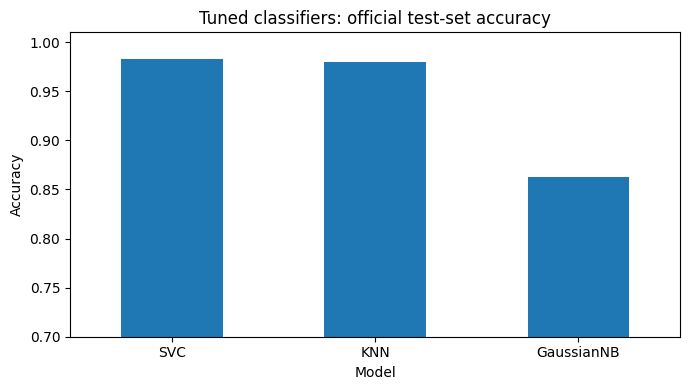

In [11]:
# Refit each classifier using all 3,823 supplied training images.
final_models = {}
final_predictions = {}
test_rows = []
for name, search in tuned_searches.items():
    final_models[name] = clone(search.best_estimator_).fit(X_full, y_full)
    prediction = final_models[name].predict(X_test)
    final_predictions[name] = prediction
    test_rows.append(scoring_row(name, 'Writer-independent test', y_test, prediction))

test_scores = pd.DataFrame(test_rows).sort_values(
    'Accuracy', ascending=False).reset_index(drop=True)
print('Final results on 1,797 original held-out writer-independent images:')
display(test_scores.style.format({
    c: '{:.2%}' for c in ['Accuracy', 'Precision', 'Recall', 'F1']
}))
print('Full classification report for the validation-selected model:', selected_name)
print(classification_report(y_test, final_predictions[selected_name], digits=3, zero_division=0))

test_scores.set_index('Model')['Accuracy'].plot(
    kind='bar', rot=0, figsize=(7, 4), ylim=(0.7, 1.01))
plt.title('Tuned classifiers: official test-set accuracy')
plt.ylabel('Accuracy')
plt.tight_layout()
plt.show()

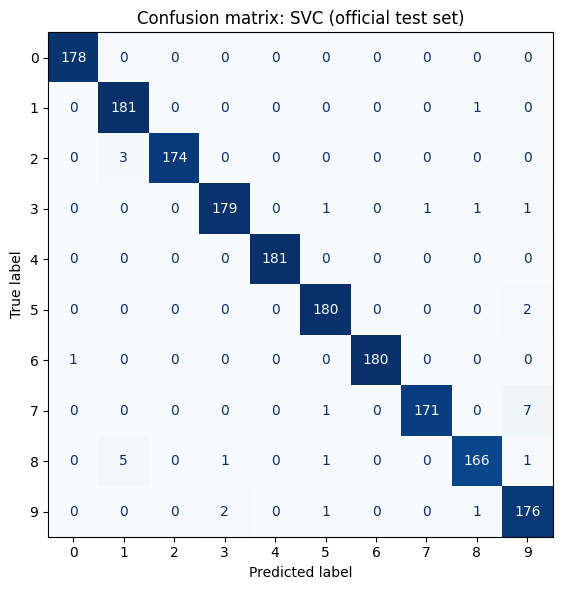

SVC: 31 incorrect predictions out of 1797 test images.


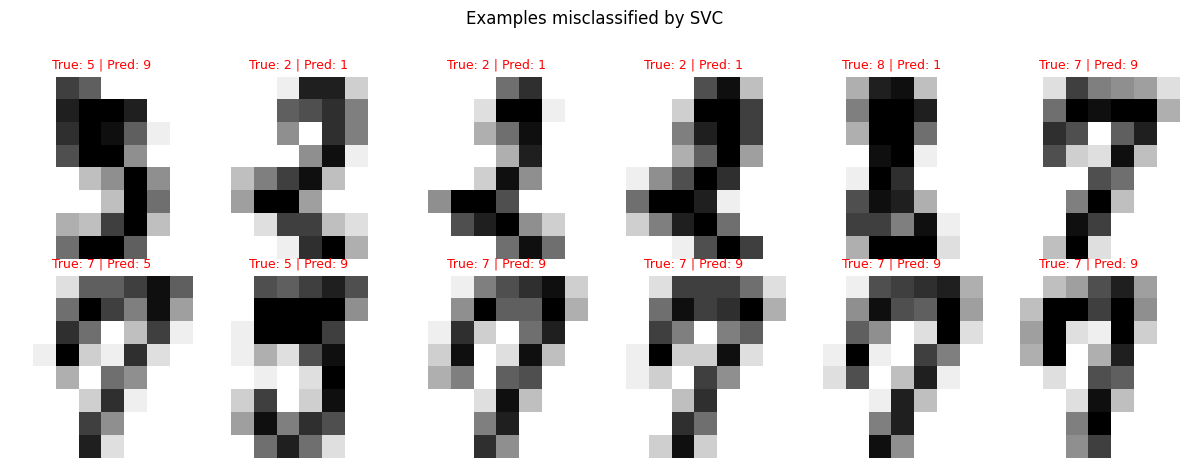

In [12]:
# Confusion matrix for the model chosen using validation results.
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, final_predictions[selected_name],
    display_labels=np.arange(10), cmap='Blues', colorbar=False,
    ax=ax, values_format='d'
)
ax.set_title(f'Confusion matrix: {selected_name} (official test set)')
plt.tight_layout()
plt.show()

# Show examples of incorrect test predictions to understand model limitations.
wrong_idx = np.flatnonzero(final_predictions[selected_name] != y_test)
print(f'{selected_name}: {len(wrong_idx)} incorrect predictions out of {len(y_test)} test images.')
if len(wrong_idx):
    show_idx = wrong_idx[:min(12, len(wrong_idx))]
    cols = 6
    rows = int(np.ceil(len(show_idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 2.3 * rows), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, j in zip(axes.ravel(), show_idx):
        ax.imshow(X_test[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=16)
        ax.set_title(f'True: {y_test[j]} | Pred: {final_predictions[selected_name][j]}',
                     fontsize=9, color='red')
        ax.axis('off')
    fig.suptitle(f'Examples misclassified by {selected_name}', y=1.02)
    plt.tight_layout()
    plt.show()

## Discussion and conclusion

In [13]:
val_winner = validation_scores.iloc[0]
test_winner = test_scores.iloc[0]
chosen_test = test_scores.set_index('Model').loc[selected_name]
print('FINAL CONCLUSION')
print(f'1) All three models learned the 10 classes (digits 0–9).')
print(f'2) The validation-selected model was {selected_name}: '
      f'{val_winner["Accuracy"]:.2%} validation accuracy, '
      f'{val_winner["CV Accuracy"]:.2%} cross-validation accuracy.')
print(f'3) When refitted on all 3,823 training images, {selected_name} reached '
      f'{chosen_test["Accuracy"]:.2%} accuracy and '
      f'{chosen_test["F1"]:.2%} weighted F1 on 1,797 independent test images.')
print(f'4) Highest observed official test accuracy was {test_winner["Model"]}: '
      f'{test_winner["Accuracy"]:.2%}. (This is a descriptive comparison, '
      'not an extra round of test-set tuning.)')
print('5) SVC and KNN can capture complex handwritten pixel patterns; '
      'GaussianNB offers a simpler but usually less accurate baseline.')

FINAL CONCLUSION
1) All three models learned the 10 classes (digits 0–9).
2) The validation-selected model was SVC: 98.82% validation accuracy, 99.08% cross-validation accuracy.
3) When refitted on all 3,823 training images, SVC reached 98.27% accuracy and 98.28% weighted F1 on 1,797 independent test images.
4) Highest observed official test accuracy was SVC: 98.27%. (This is a descriptive comparison, not an extra round of test-set tuning.)
5) SVC and KNN can capture complex handwritten pixel patterns; GaussianNB offers a simpler but usually less accurate baseline.


### Reproducibility and data notes

- Use Python with `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and Jupyter/IPython.
- Place `optdigits.tra` and `optdigits.tes` beside this notebook (both included in the submission ZIP). Execute cells from top to bottom.
- `random_state=42` makes the development split reproducible; cross-validation defaults to deterministic nonshuffled folds.
- The supplied `.names` file describes the data collection, 8 × 8 pixel preprocessing, 0–16 intensity range, and the train/test division by writer. The original unprocessed `.Z` files represent a different high-resolution format and are intentionally not mixed with 8 × 8 inputs.
- **Scope limitation:** These results measure recognition of the isolated, pre-cropped digit images. They do not test the additional address localization, segmentation, or whole-letter reading steps of a complete postal OCR system.